In [1]:
import pandas as pd
from matplotlib import pyplot as plt

bench = pd.read_csv("results/bench.csv")
bench["hashes_per_s"] = bench["n"] / (bench["us"] / 1e6)
stab = pd.read_csv("results/stability.csv")
stab["hashes_per_s"] = stab["n"] / (stab["us"] / 1e6)

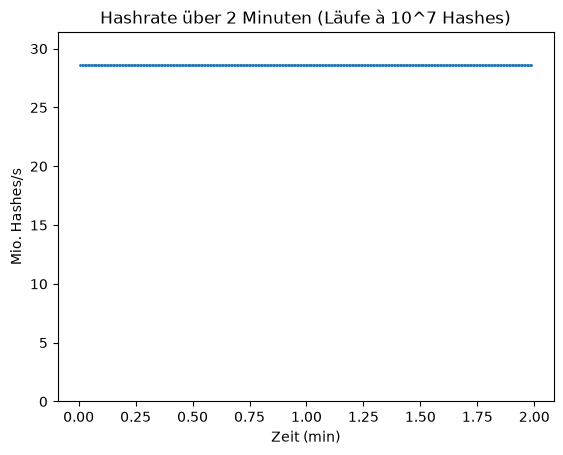

In [2]:
plt.plot(stab["t_s"] / 60, stab["hashes_per_s"] / 1e6, ".", markersize=2)
plt.ticklabel_format(axis="y", useOffset=False)
plt.ylim(0, 1.1 * stab["hashes_per_s"].max() / 1e6)
plt.xlabel("Zeit (min)")
plt.ylabel("Mio. Hashes/s")
plt.title("Hashrate über 2 Minuten (Läufe à 10^7 Hashes)")
plt.show()

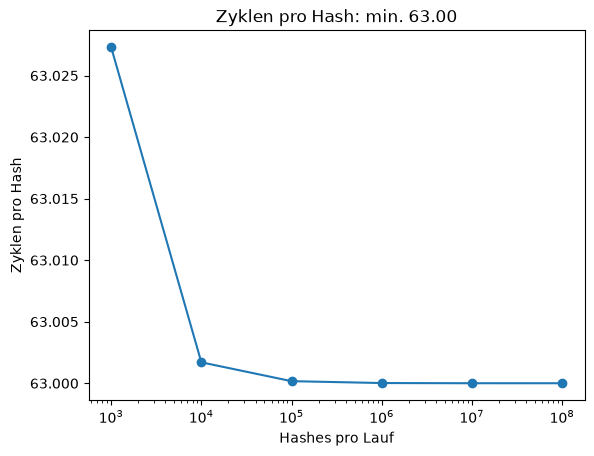

In [3]:
bench["cycles_per_hash"] = bench["cycles"] / bench["n"]
mean_cyc = bench.groupby("n")["cycles_per_hash"].mean()
plt.plot(mean_cyc.index, mean_cyc.values, "o-")
plt.xscale("log")
plt.ticklabel_format(axis="y", useOffset=False)
plt.xlabel("Hashes pro Lauf")
plt.ylabel("Zyklen pro Hash")
plt.title(f"Zyklen pro Hash: min. {mean_cyc.min():.2f}")
plt.show()


In [4]:
cycles_per_hash_no_header = 63
cycles_per_hash = 328
cycles_per_hash_with_store = 505

def calc_hashes_per_second_per_thread(cycles_per_hash):
    cpu_freq = 1.8e9  # Hz
    return cpu_freq / cycles_per_hash

hashes_per_second_per_thread = calc_hashes_per_second_per_thread(cycles_per_hash)
print(f"Hashes per second per thread: {(hashes_per_second_per_thread / 1e6):.2f} Mio.")
print(f"Hashes per second per thread (no header): {(calc_hashes_per_second_per_thread(cycles_per_hash_no_header) / 1e6):.2f} Mio.")
print(f"Hashes per second per thread (with store): {(calc_hashes_per_second_per_thread(cycles_per_hash_with_store) / 1e6):.2f} Mio.")

Hashes per second per thread: 5.49 Mio.
Hashes per second per thread (no header): 28.57 Mio.
Hashes per second per thread (with store): 3.56 Mio.


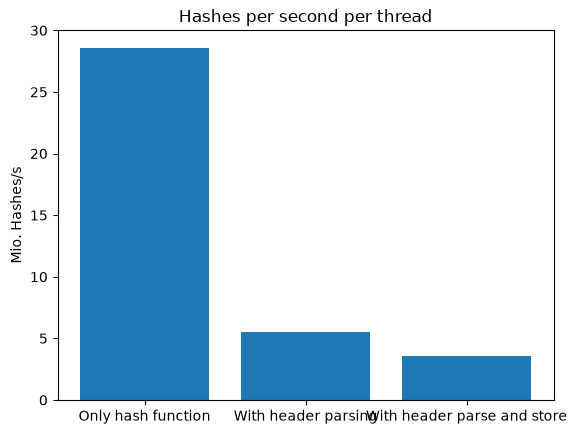

In [5]:
plt.bar(["Only hash function", "With header parsing", "With header parse and store"], [calc_hashes_per_second_per_thread(cycles_per_hash_no_header) / 1e6, calc_hashes_per_second_per_thread(cycles_per_hash) / 1e6, calc_hashes_per_second_per_thread(cycles_per_hash_with_store) / 1e6])
plt.ylabel("Mio. Hashes/s")
plt.title("Hashes per second per thread")
plt.show()